# Regime-Aware Portfolio Optimizer

## 1. Data

In [4]:
import os
import cmath as math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.cluster import KMeans
from pypfopt import expected_returns, risk_models
from pypfopt.efficient_frontier import EfficientFrontier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

os.makedirs("outputs", exist_ok=True)
os.makedirs("data", exist_ok=True)

In [5]:
tickers = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'TSLA', 'WMT', 'JNJ', 'JPM', 'XOM', 'DIS']
start_date = '2015-01-01'
end_date= '2025-01-01'

raw = yf.download(tickers,start=start_date,end=end_date,progress=False, auto_adjust=True)
raw = raw["Close"]
raw = raw.dropna(axis=1, how="all").dropna()
raw.to_csv("data/prices.csv")
raw.tail()

Ticker,AAPL,AMZN,DIS,GOOGL,JNJ,JPM,MSFT,TSLA,WMT,XOM
Date,,,,,,,,,,
2024-12-24,256.339722,229.050003,110.482231,194.965683,139.277817,232.803146,433.363495,462.279999,91.220375,100.614822
2024-12-26,257.153809,227.050003,110.472420,194.458664,139.019989,233.600601,432.160126,454.130005,91.328644,100.699928
2024-12-27,253.748535,223.750000,109.490883,191.635208,138.513885,231.707901,424.683075,431.660004,90.216438,100.690483
2024-12-30,250.382965,221.300003,108.754723,190.124100,136.880951,229.930511,419.060455,417.410004,89.143600,100.009628
2024-12-31,248.615814,219.389999,109.294563,188.195419,138.103241,230.305176,415.775696,403.839996,88.927071,101.721207



## 2. Efficient Frontier / Max-Sharpe Portfolio

In [6]:
mu = expected_returns.mean_historical_return(raw)
S= risk_models.sample_cov(raw)
ef= EfficientFrontier(mu,S)

max_sharpe_weight=ef.max_sharpe()
clean_weight=ef.clean_weights()

print("Max-Sharpe portfolio weights:")
for a,w in clean_weight.items():
    if w>0:
        print(f"{a}:{w:.2%}")

perf = ef.portfolio_performance(verbose=True)


Max-Sharpe portfolio weights:
AAPL:15.99%
AMZN:20.84%
JPM:9.94%
MSFT:17.78%
TSLA:7.04%
WMT:28.42%
Expected annual return: 23.9%
Annual volatility: 20.5%
Sharpe Ratio: 1.16


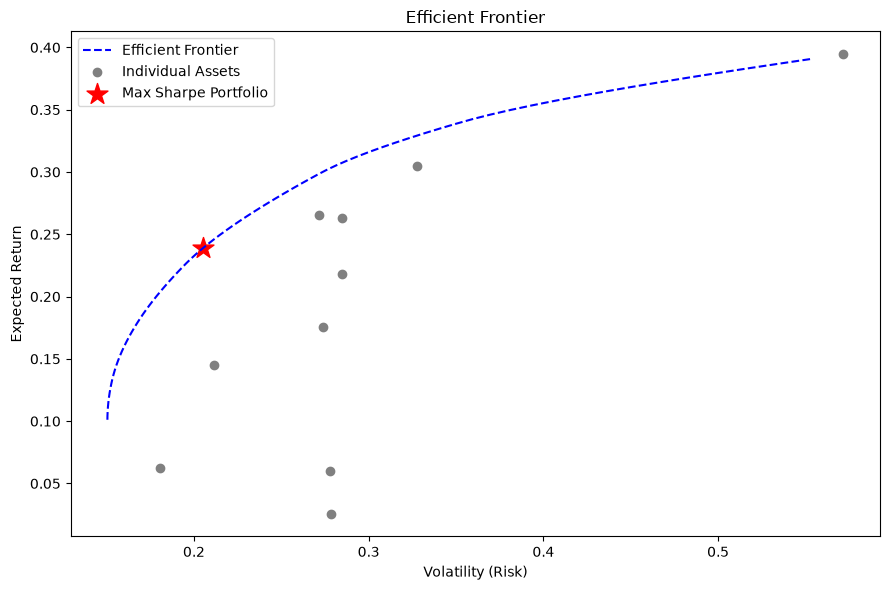

In [7]:
n = 100
risks, returns = [], []

for target in np.linspace(mu.min(), mu.max(), n):
    try:
        ef_temp= EfficientFrontier(mu,S)
        ef_temp.efficient_return(target)
        r,v,l = ef_temp.portfolio_performance()
        risks.append(v)
        returns.append(r)
    except Exception:
        continue
plt.figure(figsize=(9, 6))
plt.plot(risks, returns, "b--", label="Efficient Frontier")
plt.scatter(np.sqrt(np.diag(S)), mu, c="gray", label="Individual Assets")
plt.scatter(perf[1], perf[0], c="red", marker="*", s=250, label="Max Sharpe Portfolio")
plt.xlabel("Volatility (Risk)")
plt.ylabel("Expected Return")
plt.title("Efficient Frontier")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/efficient_frontier.png", dpi=150)
plt.show()




## 3. Regime Detection

In [8]:
market = yf.download("SPY", start=start_date, end=end_date)["Close"]
market = market.squeeze()
market_returns = market.pct_change().dropna()
ks, inertias, silhouettes =[], [], []
window = 21  
rolling_vol = market_returns.rolling(window).std() * np.sqrt(252)
rolling_ret = market_returns.rolling(window).mean() * 252
scaler = StandardScaler()

features = pd.DataFrame({
    "rolling_vol": rolling_vol,
    "rolling_ret": rolling_ret
}).dropna()

scaled_features = scaler.fit_transform(features[["rolling_vol", "rolling_ret"]])

for k in range(2,9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    ks.append(k)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(scaled_features, kmeans.labels_))
    
print(silhouettes)

[*********************100%***********************]  1 of 1 completed


[0.5499275122467753, 0.4796433160937434, 0.46024214881900827, 0.3835456498293743, 0.3943590449171979, 0.3709426300409362, 0.36020791053232687]


In [9]:
best_k = ks[silhouettes.index(max(silhouettes))]

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
features["regime"] = kmeans.fit_predict(scaled_features)

vol_means = features.groupby("regime")["rolling_vol"].mean()
volatile_cluster = vol_means.idxmax()
features["regime_label"] = features["regime"].apply(
    lambda x: "volatile" if x == volatile_cluster else "calm"
)

periods = {
    "COVID crash": ("2020-02-15", "2020-04-15"),
    "2022 selloff": ("2022-01-01", "2022-10-01"),
}

print(f"Chosen K: {best_k}\n")

print("Sanity check against known stress periods:")
for name, (start, end) in periods.items():
    subset = features.loc[start:end]
    pct = (subset["regime_label"] == "volatile").mean()
    print(f"  {name}: {pct:.0%} of days labeled volatile")

print("\nRegime counts:")
print(features["regime_label"].value_counts())

print("\nAverage features by regime:")
print(features.groupby("regime_label")[["rolling_vol", "rolling_ret"]].mean())

features.tail()

Chosen K: 2

Sanity check against known stress periods:
  COVID crash: 88% of days labeled volatile
  2022 selloff: 63% of days labeled volatile

Regime counts:
regime_label
calm        2072
volatile     423
Name: count, dtype: int64

Average features by regime:
              rolling_vol  rolling_ret
regime_label                          
calm             0.123267     0.305099
volatile         0.268323    -0.653230


,rolling_vol,rolling_ret,regime,regime_label
Date,,,,
2024-12-24,0.136351,0.165429,0,calm
2024-12-26,0.135997,0.125523,0,calm
2024-12-27,0.139988,-0.063451,0,calm
2024-12-30,0.145005,-0.164033,0,calm
2024-12-31,0.143134,-0.282231,0,calm


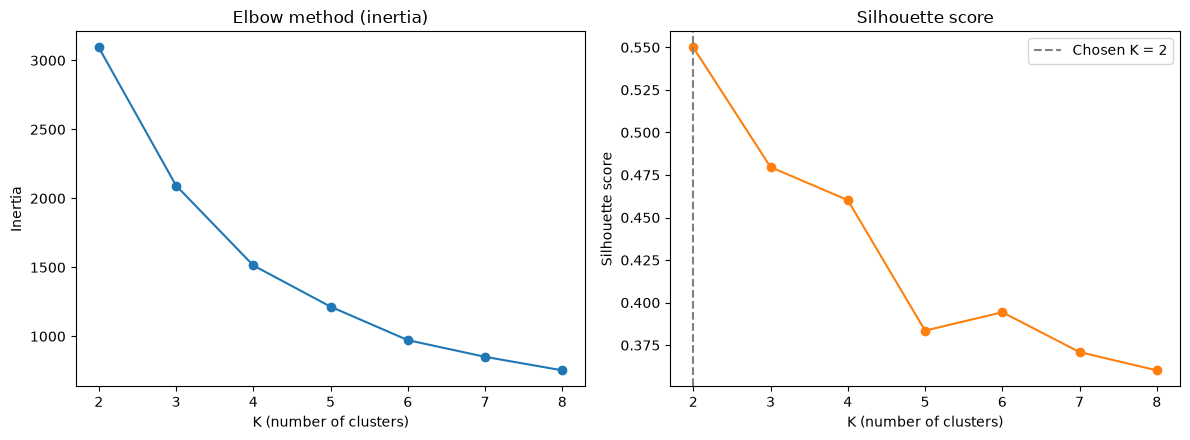

In [10]:
best_k = ks[silhouettes.index(max(silhouettes))]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(ks, inertias, "o-")
axes[0].set_title("Elbow method (inertia)")
axes[0].set_xlabel("K (number of clusters)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(ks)

axes[1].plot(ks, silhouettes, "o-", color="tab:orange")
axes[1].axvline(best_k, linestyle="--", color="gray", label=f"Chosen K = {best_k}")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("K (number of clusters)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(ks)
axes[1].legend()

plt.tight_layout()
plt.savefig("outputs/elbow_plot.png", dpi=150)
plt.show()

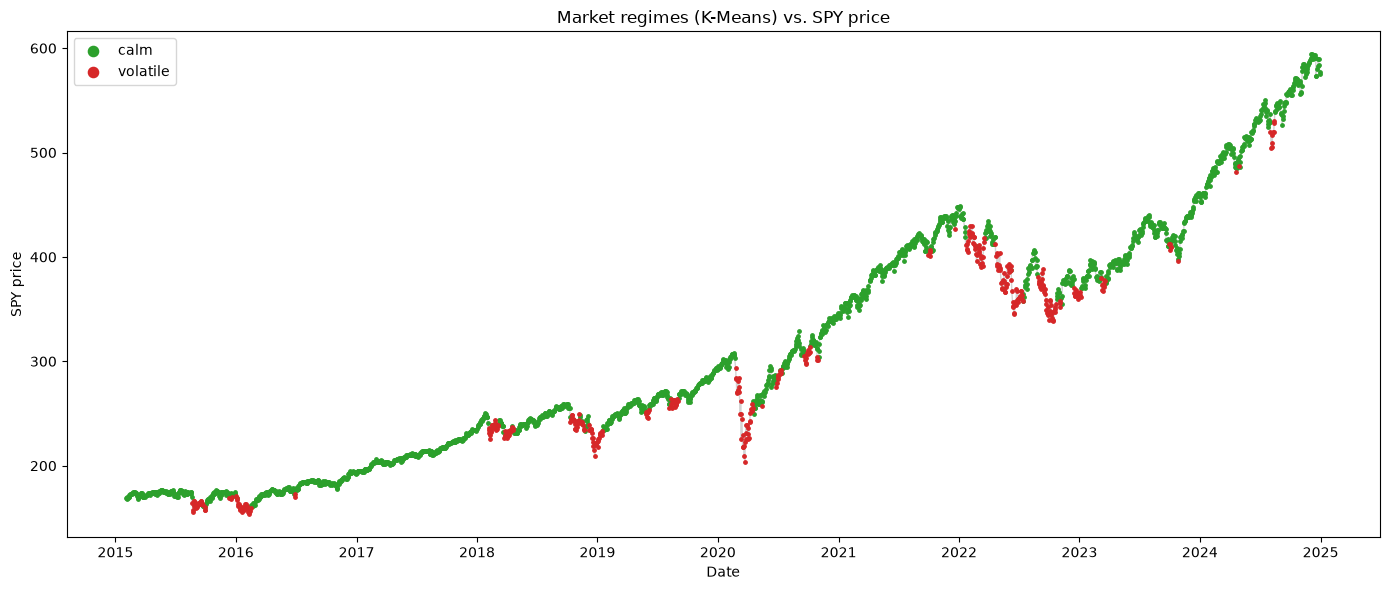

In [11]:
prices = market.loc[features.index]

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(prices.index, prices.values, color="lightgray", linewidth=1, zorder=1)

colors = {"calm": "tab:green", "volatile": "tab:red"}
for label, color in colors.items():
    mask = features["regime_label"] == label
    ax.scatter(prices.index[mask], prices[mask], s=6, color=color, label=label, zorder=2)

ax.set_title("Market regimes (K-Means) vs. SPY price")
ax.set_xlabel("Date")
ax.set_ylabel("SPY price")
ax.legend(markerscale=3)

plt.tight_layout()
plt.savefig("outputs/regime_timeline.png", dpi=150)
plt.show()

## 4. Rebalancing rule
#

In [ ]:
ef_calm = EfficientFrontier(mu, S)
ef_calm.max_sharpe()
w_calm = ef_calm.clean_weights()

ef_volatile = EfficientFrontier(mu, S)
ef_volatile.min_volatility()
w_volatile = ef_volatile.clean_weights()
w_calm = pd.Series(w_calm)[raw.columns]
w_volatile = pd.Series(w_volatile)[raw.columns]

print("Calm regime (max Sharpe):")
for asset, w in w_calm.items():
    if w > 0:
        print(f"  {asset}: {w:.2%}")

print("\nVolatile regime (min volatility):")
for asset, w in w_volatile.items():
    if w > 0:
        print(f"  {asset}: {w:.2%}")


Calm regime (max Sharpe):
  AAPL: 15.99%
  AMZN: 20.84%
  JPM: 9.94%
  MSFT: 17.78%
  TSLA: 7.04%
  WMT: 28.42%

Volatile regime (min volatility):
  AMZN: 4.89%
  DIS: 7.36%
  GOOGL: 4.09%
  JNJ: 45.05%
  TSLA: 0.07%
  WMT: 28.35%
  XOM: 10.19%
10 10
0.99999 1.00001


In [19]:
asset_returns = raw.pct_change().dropna()
asset_returns= asset_returns.loc[asset_returns.index.isin(features.index)]

month_label= features["regime_label"].groupby(features.index.to_period("M")).last()
prev_label=month_label.shift(1)

daily_label= pd.Series(
    asset_returns.index.to_period("M").map(prev_label),
    index=asset_returns.index,
)

valid = daily_label.notna()
asset_returns=asset_returns[valid]
daily_label=daily_label[valid]

print(len(asset_returns), len(daily_label))
print(daily_label.value_counts())
print(month_label.loc[pd.Period("2020-02")], daily_label.loc["2020-03"].unique())

changes = month_label[month_label != prev_label].dropna()
m = changes.index[3]
print(m, "own last label:", month_label[m], "| label used:", daily_label.loc[str(m)].unique())


2477 2477
Date
calm        1956
volatile     521
Name: count, dtype: int64
volatile <StringArray>
['volatile']
Length: 1, dtype: str
2015-12 own last label: volatile | label used: <StringArray>
['calm']
Length: 1, dtype: str


In [20]:
calm_ret = asset_returns @ w_calm
volatile_ret = asset_returns @ w_volatile

strategy_ret = calm_ret.where(daily_label == "calm", volatile_ret)
static_ret = calm_ret
equal_ret = asset_returns.mean(axis=1)

returns = pd.DataFrame({
    "regime-aware": strategy_ret,
    "static max-Sharpe": static_ret,
    "equal-weight": equal_ret,
})
print(returns.describe())

       regime-aware  static max-Sharpe  equal-weight
count   2477.000000        2477.000000   2477.000000
mean       0.000930           0.001019      0.000869
std        0.011646           0.012961      0.012364
min       -0.076075          -0.104192     -0.106763
25%       -0.004355          -0.004933     -0.004666
50%        0.001296           0.001369      0.001124
75%        0.006896           0.007548      0.006962
max        0.077556           0.101502      0.091445


In [21]:
def summarize(r):
    growth = (1 + r).cumprod()
    ann_ret = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    return pd.Series({
        "Total return": growth.iloc[-1] - 1,
        "Annualized return": ann_ret,
        "Annualized volatility": ann_vol,
        "Sharpe ratio": ann_ret / ann_vol,
        "Max drawdown": (growth / growth.cummax() - 1).min(),
    })

results = returns.apply(summarize).T
print(results.round(3))

                   Total return  Annualized return  Annualized volatility  \
regime-aware              7.452              0.234                  0.185   
static max-Sharpe         9.126              0.257                  0.206   
equal-weight              6.110              0.219                  0.196   

                   Sharpe ratio  Max drawdown  
regime-aware              1.267        -0.253  
static max-Sharpe         1.248        -0.293  
equal-weight              1.116        -0.319  


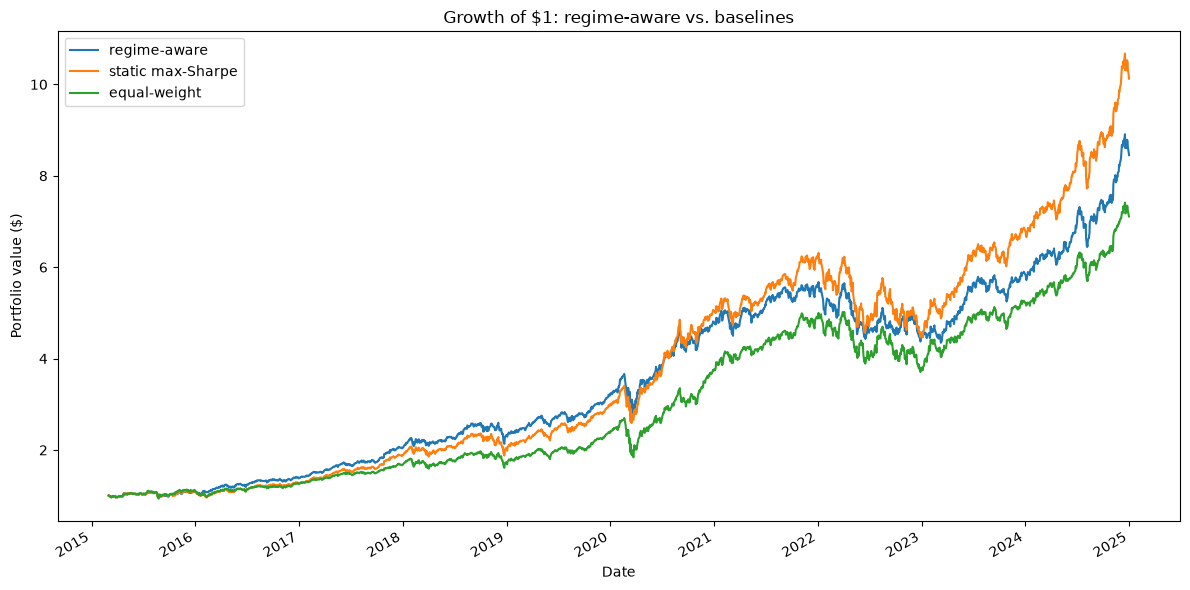

In [22]:
growth = (1 + returns).cumprod()

fig, ax = plt.subplots(figsize=(12, 6))
growth.plot(ax=ax)
ax.set_title("Growth of $1: regime-aware vs. baselines")
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio value ($)")
plt.tight_layout()
plt.savefig("outputs/backtest_comparison.png", dpi=150)
plt.show()

In [23]:
results.to_csv("outputs/results_stocks_only.csv")